In [5]:
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from collections import defaultdict

from scipy.sparse import csr_matrix, diags, eye
from scipy.sparse.linalg import eigsh, lobpcg
from scipy.linalg import eigh
import networkx as nx

from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score

import time

import tqdm
from scipy.sparse.linalg import norm

import matplotlib.pyplot as plt

from utils import *

In [6]:
n_clusters = 10


In [7]:
import h5py
with h5py.File("./datasets/usps/usps.h5", 'r') as hf:
    train = hf.get('train')
    X = train.get("data")[:]
    y = train.get('target')[:]

# W_G = build_knn_graph(X, 10, False)
# G = nx.from_scipy_sparse_matrix(W_G)

In [8]:
random_state = 43
print("random state = ",random_state)
W_G = build_knn_graph(np.reshape(X, (len(X), -1)), k=5, use_gaussian=False, sigma=2)
G = nx.from_scipy_sparse_matrix(W_G)

deg_g = np.array(W_G.sum(axis=1)).ravel()
normalized_Lap_G = normalized_laplacian_from_D_sp(W_G, (deg_g))
sc_labels, _, _ = spectral_clustering(
    normalized_Lap_G, 
    n_clusters=n_clusters,
    random_state=random_state
)
sc_ari = adjusted_rand_score(y, sc_labels)
sc_nmi = normalized_mutual_info_score(y, sc_labels)
sc_cut = max(conductance_all_clusters(G, sc_labels).values())
print("Spectral Clustering ARI between clustering and true labels:", sc_ari)
print("Spectral Clustering NMI between clustering and true labels:", sc_nmi)
print("Spectral clustering cut: ", sc_cut)


random state =  43


C:\Users\songs\AppData\Local\Temp\ipykernel_39704\765439744.py:4: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  G = nx.from_scipy_sparse_matrix(W_G)


Spectral Clustering ARI between clustering and true labels: 0.6410759331606906
Spectral Clustering NMI between clustering and true labels: 0.7830374433146648
Spectral clustering cut:  0.07505169687385962


In [9]:

aris = []
nmis = []
aris.append(sc_ari)
nmis.append(sc_nmi)
cut_gh = []
cut_g = []
cut_g.append(sc_cut)
cut_gh.append(None)
pred_labels = sc_labels
n_neighbors = 5
neighbor_max = 1200
for i in range(10):
    W_H = build_cannot_link_graph(pred_labels, n_cl=min(n_neighbors + i, neighbor_max), random_state=random_state)
    H = nx.from_scipy_sparse_matrix(W_H)
    pred_labels, vals, vecs = iterative_clustering(W_G, W_H, k = n_clusters, exact=False, eps = 0.97, random_seed=random_state)
    # print("vals   ", vals)
    generalized_spectral_clustering_ari = adjusted_rand_score(y, pred_labels)
    generalized_spectral_clustering_nmi = normalized_mutual_info_score(y, pred_labels)
    print(f"{i+1}th iteration: Constrained Spectral Clustering ARI: {generalized_spectral_clustering_ari:.4f}")
    print(f"{i+1}th iteration: Constrained Spectral Clustering NMI: {generalized_spectral_clustering_nmi:.4f}")
    generalized_cutratio = max(ratiocut_all_clusters(G, H, pred_labels).values())
    print("cutratio ", generalized_cutratio)
    generalized_spectral_clustering_cut = max(conductance_all_clusters(G, pred_labels).values())
    print("Conductance ", generalized_spectral_clustering_cut)
    aris.append(generalized_spectral_clustering_ari)
    nmis.append(generalized_spectral_clustering_nmi)
    cut_g.append(generalized_spectral_clustering_cut)
    cut_gh.append(generalized_cutratio)
    


C:\Users\songs\AppData\Local\Temp\ipykernel_39704\3370379054.py:14: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)


1th iteration: Constrained Spectral Clustering ARI: 0.6470
1th iteration: Constrained Spectral Clustering NMI: 0.7859
cutratio  0.05651537335285505
Conductance  0.07285768214420536


C:\Users\songs\AppData\Local\Temp\ipykernel_39704\3370379054.py:14: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)


2th iteration: Constrained Spectral Clustering ARI: 0.7535
2th iteration: Constrained Spectral Clustering NMI: 0.8317
cutratio  0.05109585423818326
Conductance  0.07698428486174656


C:\Users\songs\AppData\Local\Temp\ipykernel_39704\3370379054.py:14: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)


...

8th iteration: Constrained Spectral Clustering ARI: 0.7589
8th iteration: Constrained Spectral Clustering NMI: 0.8360
cutratio  0.022897374096156286
Conductance  0.07291456271460312


C:\Users\songs\AppData\Local\Temp\ipykernel_39704\3370379054.py:14: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)


9th iteration: Constrained Spectral Clustering ARI: 0.7758
9th iteration: Constrained Spectral Clustering NMI: 0.8367
cutratio  0.022158559401309636
Conductance  0.07584550730438262


C:\Users\songs\AppData\Local\Temp\ipykernel_39704\3370379054.py:14: DeprecationWarning: 

The scipy.sparse array containers will be used instead of matrices
in Networkx 3.0. Use `from_scipy_sparse_array` instead.
  H = nx.from_scipy_sparse_matrix(W_H)


10th iteration: Constrained Spectral Clustering ARI: 0.7584
10th iteration: Constrained Spectral Clustering NMI: 0.8363
cutratio  0.020157138986724464
Conductance  0.0747588424437299


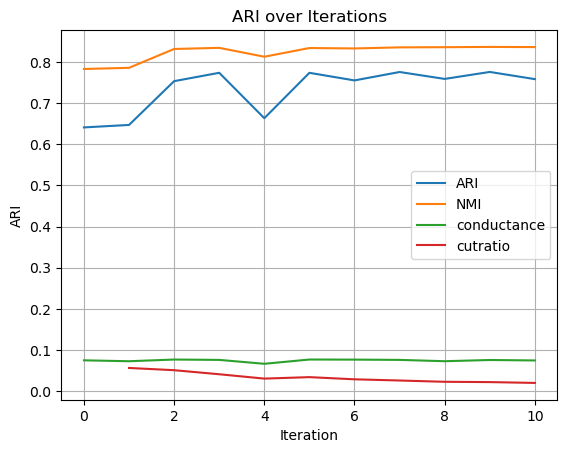

In [10]:
plt.plot(aris, label = "ARI")
plt.plot(nmis, label = "NMI")
plt.plot(cut_g, label = "conductance")
plt.plot(cut_gh, label = "cutratio")
plt.xlabel('Iteration')
plt.ylabel('ARI')
plt.title('ARI over Iterations')
plt.legend()
plt.grid()
plt.show()
